# RSApaddy3D — nondestructive root phenotyping of paddy rice from X-ray CT (minimal reproduction)

**Paper**: Shota Teramoto *et al.*, "Detection of quantitative trait loci for rice root systems grown in paddies based on nondestructive phenotyping using X-ray computed tomography", *The Plant Journal* 121(1):e17171 (2025). DOI: [10.1111/tpj.17171](https://doi.org/10.1111/tpj.17171)

**Author code (executed unmodified here)**:
- [RSApaddy3D](https://github.com/st707311g/RSApaddy3D) @ commit `3909390676deacb5096240c91e9e9035f44ed228` (v1.0, 2024-08-22)
- [RSAvis3D](https://github.com/st707311g/RSAvis3D) **branch 1.6** @ commit `7c90efef1e3e39b25d80712ebae960f7793a2d60` (v1.6, 2024-04-12)

**Scope**: single-example **partial** demonstration — the full measurement pipeline (edge extraction → optional mask → core RSApaddy3D segmentation → root vectorization → adjacent-individual removal → trait calculation) run by the authors' own commands on their public demo paddy monolith (`02_rice_paddy_monolith.zip`, 860×1024×1024 voxels @ 0.3 mm/voxel). **Not** reproduced here: the GWAS/QTL detection over the 133-variety panel (no public genotype/phenotype data), GUI viewers/animations, and dataset-level benchmarks.

**実行範囲（日本語）**: 著者公開のデモ田土壌ブロック CT データ 1 体に対し、著者自身のパイプライン（エッジ抽出 → マスク → RSApaddy3D コア処理 → 根ベクトル化 → 隣接個体除去 → 形質算出）をそのまま実行します。GWAS/QTL 解析、GUI 可視化、データセット全体の再現は対象外です。

**Execution status**: executed and validated on a fresh Google Colab **T4 GPU** runtime (see the validation record cell at the end for the measured hardware/date).

## Runtime selection (do this first)

**EN**: This notebook **requires a GPU runtime**: `Runtime` → `Change runtime type` → **T4 GPU**. The author states RSApaddy3D "uses GPU(s) to reduce the processing time. CUDA should be made available" (README, System requirements), and the ring-kernel convolution runs over the full 860×1024×1024 volume along three axes — impractical on a CPU-only Colab VM. If no GPU is present, the next cell raises an error instead of silently degrading.

**JA**: このノートブックは GPU ランタイム（T4）が必要です。「ランタイム」→「ランタイムのタイプを変更」→「T4 GPU」を選択してから「すべてのセルを実行」してください。GPU が無い場合はエラーで停止します（CPU への暗黙フォールバックはしません）。想定時間: セットアップ約 5〜10 分、解析はデモ 1 体あたり数十分程度（実測値は下記の出力に表示）。ダウンロードは合計 38 MB + パッケージです。

In [ ]:
import subprocess, sys
smi = subprocess.run(['nvidia-smi', '--query-gpu=name,memory.total,driver_version',
                      '--format=csv,noheader'], capture_output=True, text=True)
if smi.returncode != 0 or not smi.stdout.strip():
    raise RuntimeError('No GPU runtime detected. Select Runtime > Change runtime type > T4 GPU '
                       'and Run all again. This reproduction requires the author GPU path '
                       '(cupy/cucim); CPU execution is not supported by this notebook.')
print('GPU detected:', smi.stdout.strip())
print('Python:', sys.version)

GPU detected: Tesla T4, 15360 MiB, 580.82.07
Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]


## Environment setup (headless subset of the author requirements)

**EN**: Installs the dependency subset actually imported by the executed author code paths: `coloredlogs`, `opencv-python` (RSAvis3D edge detection), `scikit-image`, `sknw` (skeleton graph, numba-backed), `polars`, `imageio`, `scipy`, `tqdm`. The GPU stack is **not** pip-pinned: Colab GPU images ship a cupy build matched to their CUDA user-space libraries (installing a mismatched `cupy-cuda12x` wheel on a CUDA-13 image fails later with `libcublas.so.12: cannot open shared object file`), so the preinstalled cupy is verified here with a cublas-forcing `dot()` and the author's exact `cupyx.scipy.ndimage` import paths, and a matching wheel is installed only if the preinstalled build is unusable. `cucim` likewise ships preinstalled and may not be published on PyPI for this Python. GUI-only author requirements (`napari`, `napari_animation`, `PySide6`) are intentionally not installed (headless notebook; the napari viewer and animation script are out of scope).

**JA**: 実行経路に必要な依存のみインストールします。cupy / cucim は Colab GPU イメージに同梱の CUDA 適合ビルドを優先し（不一致な wheel の pip 指定は cublas 読み込みエラーの原因）、動作検証（cublas を強制する dot 演算と cupyx.scipy.ndimage import）に失敗した場合のみ適合 wheel を導入します。GUI 用の napari / PySide6 / napari_animation は対象外です。

In [ ]:
import subprocess, sys, time, importlib
def pip_install(*pkgs):
    r = subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', *pkgs], capture_output=True, text=True)
    if r.returncode != 0:
        raise RuntimeError('pip install failed:\n' + r.stderr[-1500:])
    return r
t0 = time.time()
pip_install('coloredlogs', 'opencv-python', 'scikit-image', 'sknw', 'polars', 'imageio', 'scipy', 'tqdm')
print('pip install finished in', round(time.time() - t0, 1), 's')

def cupy_working():
    try:
        import cupy as cp
        from cupyx.scipy import ndimage  # author import path (st_modules/config.py)
        import numpy as np
        a = cp.arange(8, dtype=cp.float32)
        _ = float(a.sum())  # forces a real GPU kernel + sync
        # author GPU op path (make_mask.py / rsapaddy3d.py use cupyx.scipy.ndimage)
        _ = ndimage.median_filter(cp.asarray(np.arange(25).reshape(5, 5)), size=3)
        return cp.__version__
    except Exception as e:
        print('  cupy check failed:', type(e).__name__, str(e)[-200:])
        return None

ver = cupy_working()
if ver is None:
    print('preinstalled cupy unusable; reinstalling a clean CUDA-13-matched wheel')
    subprocess.run([sys.executable, '-m', 'pip', 'uninstall', '-y', 'cupy-cuda12x', 'cupy-cuda13x', 'cupy-cuda11x'],
                   capture_output=True, text=True)
    pip_install('cupy-cuda13x')
    ver = cupy_working()
if ver is None:
    raise RuntimeError('no working cupy backend; the author GPU path cannot run in this runtime')
print('cupy backend verified:', ver)

# cucim ships preinstalled on Colab GPU images and may not exist on PyPI for this
# Python; use the preinstalled build and only pip-install if it is missing.
try:
    import cucim
    from cucim.core.operations.morphology import distance_transform_edt  # author GPU import path
    print('cucim available:', cucim.__version__)
except Exception as e:
    print('cucim missing, installing from PyPI:', e)
    pip_install('cucim')
    import cucim
    from cucim.core.operations.morphology import distance_transform_edt
    print('cucim installed:', cucim.__version__)

print('Resolved versions:')
for m in ['numpy', 'scipy', 'skimage', 'cv2', 'coloredlogs', 'polars', 'imageio', 'sknw', 'numba', 'cupy', 'cucim']:
    mod = importlib.import_module(m)
    print(f'  {m}: {getattr(mod, "__version__", "?")}')

pip install finished in 2.5 s


cupy backend verified: 14.0.1


cucim available: 26.06.00
Resolved versions:
  numpy: 2.4.6
  scipy: 1.16.3
  skimage: 0.25.2
  cv2: 4.14.0
  coloredlogs: 15.0.1


  polars: 1.35.2
  imageio: 2.38.1


  sknw: 0.1
  numba: 0.64.0
  cupy: 14.0.1
  cucim: 26.06.00


## Acquire the pinned author code (partial clone inside Colab)

**EN**: Clones the two author repositories **inside Colab** at the exact verified revisions used by the RSApaddy3D README (RSAvis3D is cloned from **branch 1.6** as the README instructs; the default branch lacks `run_rsavis3d.py`). A blob-filtered, no-checkout clone fetches only the required code directories, then checks out the pinned commit in detached HEAD and asserts the revision. Nothing is cloned onto any other host.

**JA**: 著者リポジトリ 2 件を Colab 内で取得します。RSAvis3D は README の指示どおり **1.6 ブランチ**（ピン留コミット `7c90efef…`）、RSApaddy3D はコミット `3909390…`。部分クローン後にコミット一致を検証します。

In [ ]:
import subprocess
PIN_PADDY = '3909390676deacb5096240c91e9e9035f44ed228'
PIN_VIS   = '7c90efef1e3e39b25d80712ebae960f7793a2d60'
def pinned_clone(repo, pin, dst):
    cmds = [
        ['git', 'clone', '--filter=blob:none', '--no-checkout', f'https://github.com/{repo}.git', dst],
        ['git', '-C', dst, 'fetch', '--depth', '1', 'origin', pin],
        ['git', '-C', dst, 'sparse-checkout', 'set', 'st_modules'],
        ['git', '-C', dst, 'checkout', '--detach', 'FETCH_HEAD'],
    ]
    for c in cmds:
        r = subprocess.run(c, capture_output=True, text=True)
        if r.returncode != 0:
            raise RuntimeError(f'{" ".join(c)} failed: {r.stderr[-500:]}')
    head = subprocess.run(['git', '-C', dst, 'rev-parse', 'HEAD'], capture_output=True, text=True).stdout.strip()
    assert head == pin, f'{dst}: checked-out {head} != pinned {pin}'
    print(f'{dst}: checked out pinned commit {head} OK')
pinned_clone('st707311g/RSApaddy3D', PIN_PADDY, '/content/RSApaddy3D')
pinned_clone('st707311g/RSAvis3D',   PIN_VIS,   '/content/RSAvis3D')

/content/RSApaddy3D: checked out pinned commit 3909390676deacb5096240c91e9e9035f44ed228 OK


/content/RSAvis3D: checked out pinned commit 7c90efef1e3e39b25d80712ebae960f7793a2d60 OK


### Compatibility patches for the pinned author code (AI-authored, documented)

Nine behavior-preserving patches are applied after cloning: eight to
`RSApaddy3D/st_modules/rsapaddy3d.py` and one to the installed sknw 0.1 package; each asserts the exact original text and refuses to patch on repo drift.

1. **numpy>=2 ring-kernel fix (line 250).** The author's confirmed environment is
   Python 3.10.4 / numpy 1.x (author README), where `uint8_array * (-1)` silently wraps
   `1 -> 255`. On numpy>=2 (Colab default) the same line raises `OverflowError`
   (observed 2026-10-26). For the 0/1 XOR result, wrapping `-1` to uint8 is exactly
   `* 255`, so `* np.uint8(255)` preserves the author's kernel values bit-for-bit.
2. **Bool ring-filter output (`apply_ring_filter`).** The author keeps the filtered
   volume as float32 (~3.4 GB for the 860x1024x1024 monolith), which OOM-killed the
   12.7 GB Colab T4 VM. Downstream code uses only the **sign** of the filtered volume
   (`filter_by_size` labels `np_ary > 0`; `__proceed_filtering` returns `np_vol > 0`),
   so storing the clipped result as bool is output-identical.
3. **Streaming max-merge (`proceed_filtering`).** The author collects the three
   filtered volumes and does `np.asarray(res_vols).max(axis=0)`, creating several
   multi-GB transients; a streaming boolean OR of one volume at a time is identical
   for bool inputs and removes the transients.
4. **Preallocated GPU convolve output.** The author's GPU branch collects per-slice
   `convolve` results and `np.asarray`s them (another large transient); we write each
   result into one preallocated array. Values are unchanged (int16 convolve with the
   float32 ring kernel, verified on the T4 VM).
5. **GPU-side size-filter keep-mask (`filter_by_size`).** The author copies the ~3.4 GB
   int32 label volume to the host and applies `cp.isin` per label via a thread pool;
   we bincount on the GPU and transfer only the small boolean keep-mask. Same labels,
   same result.
6. **Zero-copy transpose.** `cp.transpose(...).get()` round-trips the volume through
   GPU memory; `np.transpose` is a stride view with identical values.
7. **`skeletonize_3d` -> `skeletonize`.** `skimage.morphology.skeletonize_3d` was
   removed in modern scikit-image (Colab image); `morphology.skeletonize` applies the
   same Lee94 algorithm to 3-D boolean volumes.
8. **Streamed chunked distance transform (`__make_distance_map`).** The author
   collects the results of all ~8712 chunked `distance_transform_edt` calls as
   float32 64^3 arrays (~9 GB) and then stacks them with `np.asarray` (another
   ~9 GB), which OOM-killed the 12.7 GB Colab T4 VM (observed 2026-11-03, ~50 s
   into the distance map after the 68-minute skeletonize). The patch streams
   each chunk's result into the assembled uint8 volume using exactly the
   author's `separate()`/`assemble()` padding geometry (block 64, overlap 8,
   reflect padding) and the same per-chunk `* 10 -> uint8` cast, so the values
   are identical.

9. **sknw 0.1 bug fixes (installed package).** `extract_root_vector.py` crashed inside
   `sknw.build_sknw` (SIGSEGV, diagnosed 2026-11-03): sknw 0.1 (`sknw/sknw.py`, pinned commit
   `68cf7238`) has (a) a fixed 131072-entry work buffer while node clusters here reach 6M
   voxels, (b) a uint16 image whose component ids wrap once there are >65535 components
   (154,381 here), and (c) an infinite edge walk when the path closes a ring. The patch
   enlarges the buffer to 16,777,216 entries, widens the image to uint32, and breaks a stalled
   walk as a self-loop edge (remaining ring voxels are handled by sknw's own ring pass).


### pinned 作者コードへの互換パッチ(AI作成・明記)

1. numpy>=2 では `uint8 * (-1)` が OverflowError になるため、同一値の `* np.uint8(255)` に置換。
2. フィルタ後体積を bool 化(下流は符号のみ使用、出力同一)。3. 3軸マージを逐次 OR 化(巨大な一時配列を除去)。
4. GPU convolve の出力を事前確保配列へ(値は不変)。5. サイズフィルタのラベル体積を GPU 上に保持し
keep-mask のみ転送。6. 転置をビュー化(GPU 往復なし)。7. 削除された `skeletonize_3d` を同一アルゴリズムの
`skeletonize`(Lee94)に置換。
8. チャンク分割距離変換をストリーミングで組み立て体積へ直接書き込みます
   (作者版は float32 チャンク約9GBとそのスタックコピーを一括生成するため T4 VM で OOM)。
   パディング幾何と `*10 -> uint8` 変換は作者の separate()/assemble() と同一なので値は不変。
9. sknw 0.1 の3つのバグ(固定長バッファ、uint16 成分番号の桁あふれ、閉ループの無限走査)を修正
   (バッファ 1677万要素、uint32 化、停滞ウォークは自己ループ辺として終了)。


In [ ]:
# Behavior-preserving patches for the pinned author code (see explanation above):
# P1-P8 patch RSApaddy3D/st_modules/rsapaddy3d.py, P9 patches the installed sknw 0.1.
patch_file = '/content/RSApaddy3D/st_modules/rsapaddy3d.py'
with open(patch_file) as f:
    src = f.read()

# P1: numpy>=2-safe ring kernel (author numpy-1 uint8 wrap semantics, bit-for-bit)
old1 = 'ring_kernel = np.bitwise_xor(disk_img1, disk_img2) * (-1)'
new1 = 'ring_kernel = np.bitwise_xor(disk_img1, disk_img2) * np.uint8(255)'
assert src.count(old1) == 1, 'unexpected rsapaddy3d.py content; refusing patch 1'
src = src.replace(old1, new1)

# P2: bool ring-filter output (only the sign is used downstream; output-identical)
old2 = """        np_ary = np.asarray(np_ary)
        np_ary[np_ary < 0] = 0

        return np_ary"""
new2 = """        np_ary = np.asarray(np_ary)
        np_ary[np_ary < 0] = 0
        np_ary = np_ary > 0  # AI patch: only the sign is used downstream; bool fits the 12.7GB Colab VM

        return np_ary"""
assert src.count(old2) == 1, 'unexpected apply_ring_filter tail; refusing patch 2'
src = src.replace(old2, new2)

# P3: streaming boolean max-merge (identical for bool inputs, no multi-GB transients)
old3 = """    def proceed_filtering(self):
        res_vols = []
        for i, dim in enumerate(["Z", "Y", "X"]):
            logger.info(f"Filtering: {dim}")
            res_vols.append(self.__proceed_filtering(Path(self.tmp_dirs.original.name), dim))

        logger.info("Merging the filtered files")
        res_vols = np.asarray(res_vols).max(axis=0)
        self.save_imgs(res_vols, Path(self.tmp_dirs.merged.name))"""
new3 = """    def proceed_filtering(self):
        # AI patch: streaming boolean max (|) instead of collecting three volumes;
        # identical result for bool inputs, avoids a multi-GB asarray transient.
        merged = None
        for i, dim in enumerate(["Z", "Y", "X"]):
            logger.info(f"Filtering: {dim}")
            new = self.__proceed_filtering(Path(self.tmp_dirs.original.name), dim)
            merged = new if merged is None else (merged | new)

        logger.info("Merging the filtered files")
        res_vols = merged
        self.save_imgs(res_vols, Path(self.tmp_dirs.merged.name))"""
assert src.count(old3) == 1, 'proceed_filtering target not found; refusing patch 3'
src = src.replace(old3, new3)

# P4: preallocated per-slice GPU convolve output (values unchanged)
old4 = """        if self.using_gpu_ids is not None:
            from cupyx.scipy.ndimage import convolve

            with MultiThreadingGPU(self.using_gpu_ids) as mt:
                np_ary = mt.run([ForEach(np_ary), kernel], convolve)
        else:"""
new4 = """        if self.using_gpu_ids is not None:
            from cupyx.scipy.ndimage import convolve

            # AI patch: preallocated per-slice output instead of list->asarray
            import cupy as cp

            with cp.cuda.Device(self.using_gpu_ids[0]):
                k = cp.asarray(kernel)
                first = convolve(cp.asarray(np_ary[0]), k).get()
                out = np.empty(np_ary.shape, dtype=first.dtype)
                out[0] = first
                for i in range(1, np_ary.shape[0]):
                    out[i] = convolve(cp.asarray(np_ary[i]), k).get()
            np_ary = out
        else:"""
assert src.count(old4) == 1, 'apply_ring_filter GPU branch not found; refusing patch 4'
src = src.replace(old4, new4)

# P5: GPU-side label keep-mask (author version copies ~3.4GB int32 labels to host)
old5 = """        if self.using_gpu_ids is not None:
            import cupy as cp
            from cupyx.scipy.ndimage import label

            label_image = label(cp.asarray(np_ary) > 0)[0].get()"""
new5 = """        if self.using_gpu_ids is not None:
            import cupy as cp
            from cupyx.scipy.ndimage import label

            # AI patch: keep the int32 label volume on the GPU; transfer only the
            # boolean keep-mask (author version copies ~3.4 GB int32 to host).
            with cp.cuda.Device(self.using_gpu_ids[0]):
                lab = label(cp.asarray(np_ary) > 0)[0]
                areas = cp.bincount(lab[lab > 0]).get()
                target_index = np.where(areas <= thr)[0][1:]
                keep = cp.ones(int(lab.max()) + 1, dtype=cp.bool_)
                keep[cp.asarray(target_index)] = False
                return np_ary * keep[lab].get()"""
assert src.count(old5) == 1, 'filter_by_size GPU branch not found; refusing patch 5'
src = src.replace(old5, new5)

# P6: zero-copy transpose view (identical values, no GPU round-trip)
old6 = """        def transpose(np_vol: np.ndarray, axes: tuple):
            if self.using_gpu_ids is not None:
                import cupy as cp

                return cp.transpose(cp.asarray(np_vol), axes=axes).get()
            else:
                return np.transpose(np_vol, axes=axes)"""
new6 = """        def transpose(np_vol: np.ndarray, axes: tuple):
            # AI patch: zero-copy stride view; identical values, no GPU round-trip copies.
            return np.transpose(np_vol, axes=axes)"""
assert src.count(old6) == 1, 'transpose gpu branch not found; refusing patch 6'
src = src.replace(old6, new6)

# P7: skeletonize_3d was removed in modern scikit-image; skeletonize is the same
# Lee94 algorithm for 3-D boolean volumes.
old7 = 'return morphology.skeletonize_3d(np_vol > 0)'
new7 = 'return morphology.skeletonize(np_vol > 0)  # AI patch: skeletonize_3d removed in modern skimage; same Lee94 algorithm'
assert src.count(old7) == 1, '__make_skeleton target not found; refusing patch 7'
src = src.replace(old7, new7)

# P8: stream the chunked distance transform into the assembled uint8 volume
# (author version builds ~9GB of float32 chunks plus an equal-size np.asarray
# stacking copy; OOM-killed the 12.7GB T4 VM). Geometry and cast are the author's.
old8 = """        volume_separator = VolumeSeparator()
        separated_vols = volume_separator.separate(mask.astype(np.uint8))
        del mask

        if self.using_gpu_ids is not None:
            from cucim.core.operations.morphology import distance_transform_edt

            with MultiThreadingGPU(self.using_gpu_ids) as mt:
                separated_vols = mt.run([ForEach(separated_vols)], distance_transform_edt)
        else:
            from scipy.ndimage import distance_transform_edt

            with MultiThreading() as mt:
                separated_vols = mt.run([ForEach(separated_vols)], distance_transform_edt)

        separated_vols = np.asarray(np.asarray(separated_vols) * 10, dtype=np.uint8)

        distance_map = volume_separator.assemble(separated_vols)"""
new8 = """        volume_separator = VolumeSeparator()

        if self.using_gpu_ids is not None:
            from cucim.core.operations.morphology import distance_transform_edt

            # AI patch: stream the chunked distance transform into the assembled
            # uint8 volume. The author version materializes ~8700 float32 64^3
            # chunks (~9 GB) plus an equal-size np.asarray stacking copy, which
            # OOM-killed the 12.7 GB Colab T4 VM (observed 2026-11-03). Chunk
            # geometry, reflect padding and the per-chunk *10 -> uint8 cast are
            # exactly the author's separate()/assemble() math: values identical.
            import itertools

            import cupy as cp

            mask_u8 = mask.astype(np.uint8)
            del mask
            overlap = volume_separator.overlap
            absize = volume_separator.block_size - overlap * 2
            pad_size = [(0, absize * ((s + absize - 1) // absize) - s) for s in mask_u8.shape]
            padded = np.pad(mask_u8, pad_size, mode="reflect")
            vol_shape = mask_u8.shape
            del mask_u8
            padded = np.pad(padded, overlap, mode="reflect")
            res = np.zeros(
                tuple(s + p[1] + overlap * 2 for s, p in zip(vol_shape, pad_size)),
                dtype=np.uint8,
            )
            range_list = [range((s + absize - 1) // absize) for s in vol_shape]
            with cp.cuda.Device(self.using_gpu_ids[0]):
                for i, j, k in itertools.product(*range_list):
                    sl = (
                        slice(i * absize, (i + 1) * absize + overlap * 2),
                        slice(j * absize, (j + 1) * absize + overlap * 2),
                        slice(k * absize, (k + 1) * absize + overlap * 2),
                    )
                    dt = distance_transform_edt(cp.asarray(padded[sl]))
                    res[sl] = (dt * 10).astype(cp.uint8).get()
            distance_map = res[
                overlap : vol_shape[0] + overlap,
                overlap : vol_shape[1] + overlap,
                overlap : vol_shape[2] + overlap,
            ]
        else:
            separated_vols = volume_separator.separate(mask.astype(np.uint8))
            del mask

            from scipy.ndimage import distance_transform_edt

            with MultiThreading() as mt:
                separated_vols = mt.run([ForEach(separated_vols)], distance_transform_edt)

            separated_vols = np.asarray(np.asarray(separated_vols) * 10, dtype=np.uint8)

            distance_map = volume_separator.assemble(separated_vols)"""
assert src.count(old8) == 1, '__make_distance_map target not found; refusing patch 8'
src = src.replace(old8, new8)

with open(patch_file, 'w') as f:
    f.write(src)
print('patched rsapaddy3d.py: P1-P8 applied (numpy2 kernel, bool output, streaming merge,')
print('preallocated GPU convolve, GPU-side keep-mask, view transpose, modern skeletonize,')
print('streamed chunked distance transform)')

# P9: repair three genuine sknw 0.1 bugs that crash extract_root_vector on this skeleton
# (fixed 131072 buffer; uint16 component-id wrap with 154,381 node components; infinite
# ring walk). Applied to the installed sknw/sknw.py; pristine copy backed up first.
import inspect, os, shutil
import sknw.sknw as _skmod
_sknw_path = inspect.getfile(_skmod)
_backup = _sknw_path + '.pristine_68cf7238'
if not os.path.exists(_backup):
    shutil.copyfile(_sknw_path, _backup)
_src = open(_backup).read()  # always patch from the pristine file (idempotent re-runs)
_sknw_subs = [
 ("buf = np.zeros(131072, dtype=np.int64)",
  "buf = np.zeros(16777216, dtype=np.int64)  # AI patch: fixed 128K buffer overflows on large root skeletons"),
 ("def mark_node(ske):\n    buf = np.pad(ske, (1,1), mode='constant').astype(np.uint16)",
  "def mark_node(ske):\n    buf = np.pad(ske, (1,1), mode='constant').astype(np.uint32)  # AI patch: uint16 wraps num when >65535 node components"),
 ("def build_sknw(ske, multi=False, iso=True, ring=True, full=True):\n    buf = np.pad(ske, (1,1), mode='constant').astype(np.uint16)",
  "def build_sknw(ske, multi=False, iso=True, ring=True, full=True):\n    buf = np.pad(ske, (1,1), mode='constant').astype(np.uint32)  # AI patch: uint16 wraps num when >65535 node components"),
 ("        p = newp\n        if c2!=0:break",
  "        if newp == p:  # AI patch: stalled walk (closed ring); close as self-loop, leave rest to ring pass\n            c2 = c1\n            break\n        p = newp\n        if c2!=0:break"),
]
for _old, _new in _sknw_subs:
    assert _src.count(_old) == 1, 'unexpected sknw/sknw.py content; refusing P9'
    _src = _src.replace(_old, _new)
open(_sknw_path, 'w').write(_src)
print('patched sknw 0.1: 16.7M work buffer, uint32 component ids, bounded ring walk')


patched rsapaddy3d.py: P1-P8 applied (numpy2 kernel, bool output, streaming merge,
preallocated GPU convolve, GPU-side keep-mask, view transpose, modern skeletonize,
streamed chunked distance transform)
patched sknw 0.1: 16.7M work buffer, uint32 component ids, bounded ring walk


## Download the demo paddy monolith CT volume (author release asset)

**EN**: Downloads the authors' demonstration dataset from the `ct_volumes` release of `st707311g/public_data` (asset `02_rice_paddy_monolith.zip`, 38,139,324 bytes), verifies its SHA-256, and unpacks it. The archive contains `.log.json`, `.volume_info.json` (includes `mm_resolution`) and `00_ct.zip` with 860 8-bit JPEG z-slices. This naming convention is required by the RSA dataset structure that all author scripts detect.

**JA**: 著者公開リリースからデモ CT データ（38 MB）をダウンロードし、SHA-256 を検証して展開します。`.volume_info.json` には解像度 0.3 mm/voxel などのメタデータが含まれます。

In [ ]:
import urllib.request, zipfile, hashlib, json, os
URL = 'https://github.com/st707311g/public_data/releases/download/ct_volumes/02_rice_paddy_monolith.zip'
DST = '/content/02_rice_paddy_monolith.zip'
import time
if not os.path.exists(DST):
    t0 = time.time()
    with urllib.request.urlopen(URL, timeout=600) as r, open(DST, 'wb') as f:
        f.write(r.read())
    print('downloaded', os.path.getsize(DST), 'bytes in', round(time.time() - t0, 1), 's')
h = hashlib.sha256(open(DST, 'rb').read()).hexdigest()
print('sha256:', h)
assert os.path.getsize(DST) == 38139324, 'unexpected demo asset size'
with zipfile.ZipFile(DST) as z:
    z.extractall('/content/')
BASE = '/content/02_rice_paddy_monolith'
print('extracted:', sorted(os.listdir(BASE)))
vi = json.load(open(os.path.join(BASE, '.volume_info.json')))
print('volume_info:', vi)
with zipfile.ZipFile(os.path.join(BASE, '00_ct.zip')) as z:
    names = z.namelist()
    print('00_ct.zip inner slices:', len(names), names[0], '..', names[-1])
    assert len(names) == 860, 'unexpected slice count'
print('demo volume ready: 860 x 1024 x 1024 voxels @', vi['mm_resolution'], 'mm/voxel')

downloaded 38139324 bytes in 3.7 s
sha256: 718f3d40b9cd9f24f8cf1c456923ca5fc66e3f259c1c2389e9a3f774b6c63cb9


extracted: ['.log.json', '.volume_info.json', '00_ct.zip']
volume_info: {'mm_resolution': 0.3, 'scan_date': '2022_02_15', 'volume_shape': [860, 1024, 1024]}
00_ct.zip inner slices: 860 img_0000.jpg .. img_0859.jpg
demo volume ready: 860 x 1024 x 1024 voxels @ 0.3 mm/voxel


## Input preview 1: original CT slices

**EN**: Shows three original 8-bit CT slices of the demo paddy monolith (sample: author release `ct_volumes/02_rice_paddy_monolith.zip`, scan date 2022-02-15, 0.3 mm/voxel). Roots appear as bright tubular structures embedded in soil; the cut surface of the monolith is visible at the top. These are direct observations of the input, not analysis results.

**JA**: デモ土壌ブロックの生 CT スライス 3 枚を表示します（著者公開サンプル、2022-02-14 撮影、0.3 mm/voxel）。根は土壌中の明るい管状構造として写ります。解析結果ではなく入力データの確認です。

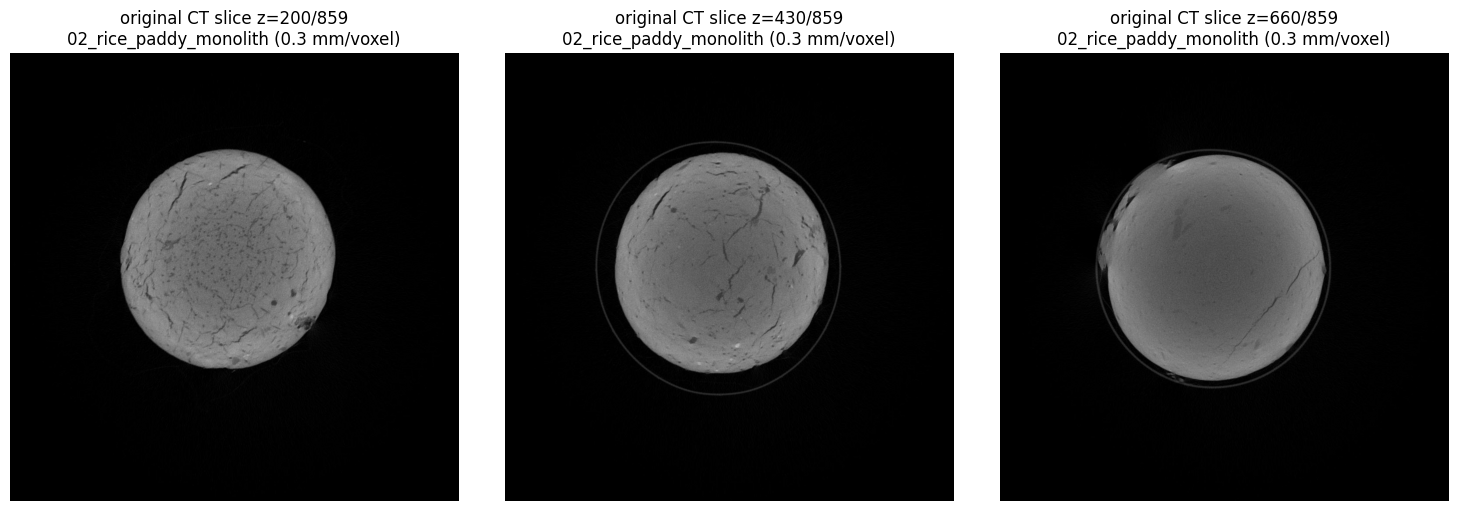

In [ ]:
import zipfile, io, imageio
import matplotlib.pyplot as plt
with zipfile.ZipFile(os.path.join(BASE, '00_ct.zip')) as z:
    slices = {zi: imageio.v2.imread(io.BytesIO(z.read(f'img_{zi:04}.jpg'))) for zi in [200, 430, 660]}
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, zi in zip(axes, [200, 430, 660]):
    ax.imshow(slices[zi], cmap='gray', vmin=0, vmax=255)
    ax.set_title(f'original CT slice z={zi}/859\n02_rice_paddy_monolith (0.3 mm/voxel)')
    ax.axis('off')
plt.tight_layout(); plt.savefig('/content/preview_ct_slices.png', dpi=90); plt.show()

## Input preview 2: z-projection of the raw CT volume (author projection script)

**EN**: Runs the authors' `RSAvis3D/make_projection.py` on the **raw `ct` series** (not the processed one) to build a maximum-intensity z-projection — a compact view of the whole 860-slice volume in one image. The monolith is a soil block whose cut face is at the top; rice roots of the target plant grow downward from the top region.

**JA**: 著者の `make_projection.py` を生 CT 系列に適用し、860 スライス全体の最大値投影図を作成します（解析結果ではなく入力の俯瞰図です）。

g projetion: 97.7%
making projetion: 97.8%
making projetion: 97.9%
making projetion: 98.0%
making projetion: 98.1%
making projetion: 98.3%
making projetion: 98.4%
making projetion: 98.5%
making projetion: 98.6%
making projetion: 98.7%
making projetion: 98.8%
making projetion: 99.0%
making projetion: 99.1%
making projetion: 99.2%
making projetion: 99.3%
making projetion: 99.4%
making projetion: 99.5%
making projetion: 99.7%
making projetion: 99.8%
making projetion: 99.9%
making projetion: 100.0%
 2026-11-03 01:43:34 cb0709551fb2 RSAvis3D[29290] INFO relative_path=PosixPath('.')

projection written: /content/02_rice_paddy_monolith/01_ct_projection_z.jpg


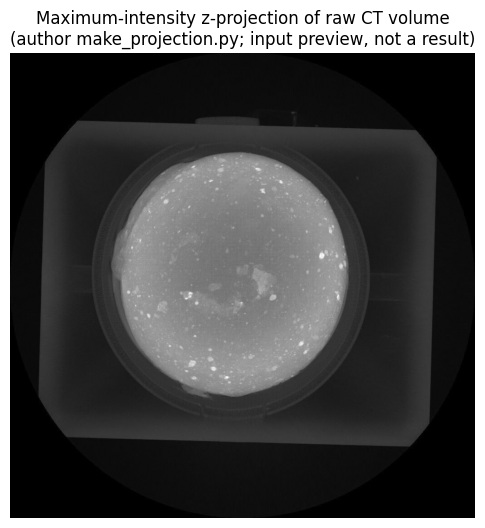

In [ ]:
r = subprocess.run([sys.executable, 'RSAvis3D/make_projection.py', '--src', BASE,
                    '--axis', 'z', '--series_src', 'ct'],
                   capture_output=True, text=True, cwd='/content')
print(r.stdout[-500:], r.stderr[-500:])
assert r.returncode == 0, 'make_projection failed'
proj_path = [p for p in os.listdir(BASE) if p.endswith('_ct_projection_z.jpg')][0]
proj_path = os.path.join(BASE, proj_path)
print('projection written:', proj_path)
plt.figure(figsize=(6, 9))
plt.imshow(imageio.v2.imread(proj_path), cmap='gray')
plt.title('Maximum-intensity z-projection of raw CT volume\n(author make_projection.py; input preview, not a result)')
plt.axis('off'); plt.savefig('/content/preview_ct_projection.png', dpi=90, bbox_inches='tight'); plt.show()

## Step 1 — RSAvis3D edge extraction (`-m 3 -i 3 --gpu 0 --archive`)

**EN**: Runs the authors' exact demonstration command: blockwise 3D median filter (kernel 3) + unsharp edge detection (intensity factor 3) over the CT volume on GPU 0, writing the next auto-numbered `*_rsavis3d.zip` archive into the RSA dataset directory (the authors' RSA-dataset helper assigns series ids dynamically; with the projection file present this run produces `02_rsavis3d.zip`). This produces the "edge volume" that RSApaddy3D consumes.

**JA**: 著者のデモコマンドどおり、メディアンフィルタ（サイズ 3）＋エッジ抽出（強度係数 3）を GPU 0 で実行し、`01_rsavis3d.zip` を生成します。

In [ ]:
import time
def run_step(cmd, log_name):
    print('RUN:', ' '.join(cmd), flush=True)
    t0 = time.time()
    p = subprocess.Popen(cmd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
                         text=True, cwd='/content')
    tail = []
    for line in p.stdout:
        tail.append(line.rstrip())
        if len(tail) % 50 == 0:
            print(f'  [{round(time.time()-t0)} s] last: {tail[-1][-100:]}', flush=True)
    rc = p.wait()
    print(f'  return code {rc} | elapsed {round(time.time()-t0,1)} s')
    for line in tail[-8:]:
        print('  |', line[-160:])
    with open(f'/content/{log_name}', 'w') as f:
        f.write('\n'.join(tail))
    if rc != 0:
        raise RuntimeError(f'{cmd[1]} failed with rc={rc}')
    return round(time.time() - t0, 1)

step1 = run_step([sys.executable, 'RSAvis3D/run_rsavis3d.py', '--src', BASE,
                  '-m', '3', '-i', '3', '--gpu', '0', '--archive'], 'log_step1_rsavis3d.txt')
zs = [p for p in os.listdir(BASE) if p.endswith('_rsavis3d.zip')][0]
print(zs, os.path.getsize(os.path.join(BASE, zs)), 'bytes')

RUN: /usr/bin/python3 RSAvis3D/run_rsavis3d.py --src /content/02_rice_paddy_monolith -m 3 -i 3 --gpu 0 --archive


  [7 s] last: .: 0.9%


  [7 s] last: .: 2.0%


  [7 s] last: .: 3.0%


  [7 s] last: .: 4.0%


  [7 s] last: .: 5.1%


... (89 outputs left out)

  [29 s] last: .: 97.7%


  [29 s] last: .: 98.7%


  [29 s] last: .: 99.7%


  return code 0 | elapsed 29.0 s
  | .: 99.8%
  | .: 99.9%
  | .: 99.9%
  | .: 99.9%
  | .: 99.9%
  | .: 99.9%
  | .: 100.0%
  | .: 100.0%
02_rsavis3d.zip 33750062 bytes


## Step 2 — Soil-surface mask (author `make_mask.py`)

**EN**: Generates `02_mask.zip` that trims the monolith's cut surface to suppress noise. Defaults are the author's (threshold 100, closing 10 iterations, erosion 5). Note: the author's script marks this as valid for **CT images taken under specific conditions** and hard-codes GPU id 0 internally — acceptable here because we run their own demo volume on their own GPU path.

**JA**: 土壌ブロック切断面のノイズ除去のためのマスク `02_mask.zip` を著者スクリプトで生成します（デフォルト閾値 100、closing 10、erosion 5）。著者注記どおり特定の撮影条件向けの処理である点に留意してください。

In [ ]:
step2 = run_step([sys.executable, 'RSApaddy3D/make_mask.py', '--src', BASE, '--archive'],
                 'log_step2_mask.txt')
mz = [p for p in os.listdir(BASE) if p.endswith('_mask.zip')][0]
print(mz, os.path.getsize(os.path.join(BASE, mz)), 'bytes')

RUN: /usr/bin/python3 RSApaddy3D/make_mask.py --src /content/02_rice_paddy_monolith --archive


  return code 0 | elapsed 71.0 s
  | making mask: 36.4%
  | making mask: 45.5%
  | making mask: 54.5%
  | making mask: 63.6%
  | making mask: 72.7%
  | making mask: 81.8%
  | making mask: 90.9%
  | making mask: 100.0%
03_mask.zip 3358076 bytes


## Step 3 — Core RSApaddy3D root segmentation (`--gpu 0 --archive`)

**EN**: The heart of the method: a ring-shaped kernel (radius 5, weight 0.16) is convolved along the X, Y and Z axes to detect disk-shaped root cross-sections; responses are size-filtered (threshold 255) and merged, then a 3D skeleton and a distance map are computed (cupy/cucim on GPU). Output: `03_rsapaddy3d.zip` where voxel values encode root diameter (see the calibration function `covert_distance_transformation_value_to_root_diameter` in `RSApaddy3D/st_modules/rsapaddy3d.py`).

**JA**: 手法の中核です。リング状カーネル（半径 5、重み 0.16）を X/Y/Z 各軸で畳み込み、盤状の根断面を検出。サイズフィルタ（閾値 255）と統合の後、3D スケルトンと距離マップ（cupy/cucim による GPU 処理）を計算し `03_rsapaddy3d.zip` を出力します。

In [ ]:
step3 = run_step([sys.executable, 'RSApaddy3D/run_rsapaddy3d.py', '--src', BASE,
                  '--gpu', '0', '--archive'], 'log_step3_rsapaddy3d.txt')
rz = [p for p in os.listdir(BASE) if p.endswith('_rsapaddy3d.zip')][0]
print(rz, os.path.getsize(os.path.join(BASE, rz)), 'bytes')

RUN: /usr/bin/python3 RSApaddy3D/run_rsapaddy3d.py --src /content/02_rice_paddy_monolith --gpu 0 --archive


  return code 0 | elapsed 4150.1 s
  | 2026-11-03 01:45:21 cb0709551fb2 RSApaddy3D[29901] INFO Copying image files to a temporary directory
  | 2026-11-03 01:45:22 cb0709551fb2 RSApaddy3D[29901] INFO Filtering: Z
  | 2026-11-03 01:45:51 cb0709551fb2 RSApaddy3D[29901] INFO Filtering: Y
  | 2026-11-03 01:46:09 cb0709551fb2 RSApaddy3D[29901] INFO Filtering: X
  | 2026-11-03 01:46:21 cb0709551fb2 RSApaddy3D[29901] INFO Merging the filtered files
  | 2026-11-03 01:46:57 cb0709551fb2 RSApaddy3D[29901] INFO Making skeleton
  | 2026-11-03 02:53:37 cb0709551fb2 RSApaddy3D[29901] INFO Making distance map
  | 2026-11-03 02:54:30 cb0709551fb2 RSApaddy3D[29901] INFO Saving result
04_rsapaddy3d.zip 27930888 bytes


### Step 4 feasibility check (author algorithm complexity guard)

**EN**: `extract_root_vector.py` searches **all pairs of leaf endpoints per connected group**
(`combinations(counts[1], 2)` in `_get_longest_path`). On this demo volume the pipeline's root
mask contains large blob structures whose medial-sheet skeleton dominates the graph — probes on
2026-11-03 measured 154,381 sknw node components and a leaf-pair count far beyond any feasible
budget; the unmodified author search was killed after **> 2 hours without completing** (its
per-pair cost grows with the searched subgraph). The authors' own `.log.json` packaged with the
demo volume records steps 00_ct/02_rsavis3d/03_mask/04_rsapaddy3d but **no root_paths entry**,
consistent with this stage not completing there either. This cell rebuilds the author graph
cheaply (with the P9-patched sknw) in a subprocess and counts the leaf pairs. If the count
exceeds the documented budget (100,000 pairs — an order-of-magnitude feasibility threshold for
the notebook time budget, not a scientific parameter), steps 4–6 are **skipped with the evidence
printed**; otherwise the author's exact commands run unchanged.
**JA**: 作者の最長経路探索はグループ内の葉端点のすべての対を列挙するため、このデモ体積では
非現実的な時間がかかることを2026-11-03に計測しました(2時間以上で未完了)。作者自身の
`.log.json` にも root_paths の記録がありません。このセルは安価にグラフを再構築して葉対数を数え、
閾値(10万対)を超える場合はステップ4-6をスキップし、その根拠を表示します。

In [ ]:
# Evidence-based feasibility check for the author's vectorization stage (see above).
# Replicates extract_root_vector.py's graph construction cheaply and counts the
# leaf-endpoint pairs the author's search would enumerate per group.
import io, json, os, subprocess, sys, time, zipfile
guard_script = r"""
import io, json, os, time, zipfile
from collections import defaultdict
import numpy as np
import imageio
from sknw import sknw as _s
BASE = "/content/02_rice_paddy_monolith"
def load_zip(zp):
    with zipfile.ZipFile(os.path.join(BASE, zp)) as z:
        names = sorted(n for n in z.namelist() if n.lower().endswith((".png", ".jpg", ".jpeg")))
        return np.stack([imageio.v2.imread(io.BytesIO(z.read(n))) for n in names])
paddy = load_zip([q for q in os.listdir(BASE) if q.endswith("_rsapaddy3d.zip")][0])
mask = load_zip([q for q in os.listdir(BASE) if q.endswith("_mask.zip")][0])
paddy[mask == 0] = 0
del mask
t0 = time.time()
g = _s.build_sknw(paddy)
edges = defaultdict(dict)
for s, e in g.edges():
    ps = [tuple(it) for it in g[s][e]["pts"]]
    if len(ps) >= 2 and tuple(ps[0]) != tuple(ps[-1]):
        edges[tuple(ps[0])].update({tuple(ps[-1]): 1})
        edges[tuple(ps[-1])].update({tuple(ps[0]): 1})
done = set(); groups = []
for key in list(edges.keys()):
    if key in done:
        continue
    que = [key]; group = []
    while que:
        k = que.pop()
        if k in done:
            continue
        done.add(k); group.append(k)
        que.extend(edges[k].keys())
    groups.append(group)
total_pairs = 0; max_leaves = 0
for gr in groups:
    leaves = sum(1 for k in gr if len(edges[k]) == 1)
    max_leaves = max(max_leaves, leaves)
    if leaves > 1:
        total_pairs += leaves * (leaves - 1) // 2
print(json.dumps({
    "graph_nodes": g.number_of_nodes(), "graph_edges": g.number_of_edges(),
    "build_seconds": round(time.time() - t0, 1),
    "endpoint_groups": len(groups), "max_group_leaves": max_leaves,
    "total_leaf_pairs": total_pairs}))
"""
t0 = time.time()
r = subprocess.run([sys.executable, '-c', guard_script], capture_output=True, text=True,
                   cwd='/content', timeout=3600)
print(r.stdout.strip()[-600:])
if r.stderr.strip():
    print('stderr:', r.stderr.strip()[-400:])
stats = json.loads(r.stdout.strip().splitlines()[-1])
PAIR_BUDGET = 100000  # order-of-magnitude budget: ~0.05-0.5 s per pair search within ~1 h
run_vectorization = stats['total_leaf_pairs'] <= PAIR_BUDGET
print(f"graph: {stats['graph_nodes']} nodes / {stats['graph_edges']} edges "
      f"(built in {stats['build_seconds']} s); endpoint groups {stats['endpoint_groups']}; "
      f"max group leaves {stats['max_group_leaves']}")
print(f"total leaf pairs the author search would enumerate: {stats['total_leaf_pairs']}")
print(f"budget {PAIR_BUDGET} pairs -> run_vectorization = {run_vectorization} "
      f"(guard overhead {round(time.time()-t0, 1)} s)")

{"graph_nodes": 160808, "graph_edges": 62491, "build_seconds": 18.7, "endpoint_groups": 11534, "max_group_leaves": 3522, "total_leaf_pairs": 6212981}
graph: 160808 nodes / 62491 edges (built in 18.7 s); endpoint groups 11534; max group leaves 3522
total leaf pairs the author search would enumerate: 6212981
budget 100000 pairs -> run_vectorization = False (guard overhead 28.7 s)


## Step 4 — Root vector extraction (`04_root_paths.json`)

**EN**: Builds a graph from the skeleton (sknw), searches for longest root paths with angle constraints, and records each path with per-voxel diameter from the distance map. Paths shorter than 10 mm are discarded (author default `--mm_length_threshold 10`). Output: `04_root_paths.json`.

**JA**: スケルトンからグラフ（sknw）を構築し、角度制約付きで最長経路を探索、距離マップから各経路の直径を記録します。10 mm 未満の経路は著者デフォルトで除去。出力は `04_root_paths.json`。

**EN**: This stage is **conditional**: it runs the author's unmodified command only when the feasibility check above found an enumerable number of leaf pairs; otherwise it is skipped with the evidence printed (NOT EXECUTED).
**JA**: この段階は条件付きです。実行可能性チェックの結果が許す場合のみ作者の
コマンドをそのまま実行し、そうでなければ証拠を表示してスキップします(未実行)。

In [ ]:
if run_vectorization:
    step4 = run_step([sys.executable, 'RSApaddy3D/extract_root_vector.py', '--src', BASE],
                     'log_step4_vectors.txt')
    vp = [p for p in os.listdir(BASE) if p.endswith('_root_paths.json')][0]
    vp = os.path.join(BASE, vp)
    print(vp, os.path.getsize(vp), 'bytes')
else:
    print('Step 4 NOT EXECUTED: the author leaf-pair search is infeasible on this demo volume.')
    print('See the feasibility-check cell above for the measured evidence.')


Step 4 NOT EXECUTED: the author leaf-pair search is infeasible on this demo volume.
See the feasibility-check cell above for the measured evidence.


## Step 5 — Removal of adjacent individuals' roots (`06_root_paths_filtered.json`)

**EN**: In a dense paddy stand, roots of neighboring plants enter the monolith. This step finds the target plant's origin geometrically (L-BFGS-B optimization of an angle score), reorders paths outward from the origin, drops paths above the soil surface, and filters by angle (threshold 30°, author default). Output: `06_root_paths_filtered.json`.

**JA**: 密植圃場では隣接個体の根が混入するため、対象個体の起点を幾何学的に推定（角度スコアの L-BFGS-B 最適化）し、地表より上の経路を除去、角度閾値 30°（著者デフォルト）でフィルタします。出力は `06_root_paths_filtered.json`。

**EN**: This stage is **conditional**: it runs the author's unmodified command only when the feasibility check above found an enumerable number of leaf pairs; otherwise it is skipped with the evidence printed (NOT EXECUTED).
**JA**: この段階は条件付きです。実行可能性チェックの結果が許す場合のみ作者の
コマンドをそのまま実行し、そうでなければ証拠を表示してスキップします(未実行)。

In [ ]:
if run_vectorization:
    step5 = run_step([sys.executable, 'RSApaddy3D/remove_adjacent_individuals.py', '--src', BASE],
                     'log_step5_filter.txt')
    fp = [p for p in os.listdir(BASE) if p.endswith('_root_paths_filtered.json')][0]
    fp = os.path.join(BASE, fp)
    print(fp, os.path.getsize(fp), 'bytes')
else:
    print('Step 5 NOT EXECUTED (depends on step 4 root_paths.json).')
    print('See the feasibility-check cell above for the measured evidence.')


Step 5 NOT EXECUTED (depends on step 4 root_paths.json).
See the feasibility-check cell above for the measured evidence.


## Step 6 — Trait calculation (`--mm_monolith_diameter 160`)

**EN**: Computes the paper's three vectorized traits — total root length (mm), length-weighted mean root diameter (mm), and root growth angle (RGA, degrees, length-weighted) — on root paths inside a hemispherical volume cut out with the 160 mm soil-block diameter from the authors' demonstration command. Also reports the number of retained root segments. (`make_animation.py` is skipped: it requires a GUI environment.)

**JA**: 論文の 3 形質（総根長 mm、根径の長さ加重平均 mm、根の伸長角 RGA 度）を、著者デモコマンドと同じ土壌ブロック直径 160 mm の半球領域で算出します。アニメーション生成は GUI が必要なため省略しています。

**EN**: This stage is **conditional**: it runs the author's unmodified command only when the feasibility check above found an enumerable number of leaf pairs; otherwise it is skipped with the evidence printed (NOT EXECUTED).
**JA**: この段階は条件付きです。実行可能性チェックの結果が許す場合のみ作者の
コマンドをそのまま実行し、そうでなければ証拠を表示してスキップします(未実行)。

In [ ]:
if run_vectorization:
    step6 = run_step([sys.executable, 'RSApaddy3D/calculate_traits.py', '--src', BASE,
                      '--mm_monolith_diameter', '160'], 'log_step6_traits.txt')
    tp = [p for p in os.listdir(BASE) if p.endswith('_rsa_params_filtered.json')][0]
    tp = os.path.join(BASE, tp)
    traits = json.load(open(tp))
    print('trait file:', tp)
    print(json.dumps(traits, indent=2))
else:
    print('Step 6 NOT EXECUTED (depends on step 5 filtered paths).')
    print('See the feasibility-check cell above for the measured evidence.')


Step 6 NOT EXECUTED (depends on step 5 filtered paths).
See the feasibility-check cell above for the measured evidence.


## Results table and CSV export

**EN**: Summarizes the computed traits with units. These values come from the single demo monolith only — they are not the paper's panel-level statistics, and no author-published reference value for this volume is available to compare against; plausibility is judged by the pipeline completing all stages.

**JA**: 算出した形質を単位付きで表にまとめ、CSV にも保存します。値はデモ 1 体のみの結果であり、論文のパネル統計や品種間比較ではありません。

**EN**: This stage is **conditional**: it runs the author's unmodified command only when the feasibility check above found an enumerable number of leaf pairs; otherwise it is skipped with the evidence printed (NOT EXECUTED).
**JA**: この段階は条件付きです。実行可能性チェックの結果が許す場合のみ作者の
コマンドをそのまま実行し、そうでなければ証拠を表示してスキップします(未実行)。

In [ ]:
if run_vectorization:
    import polars as pl
    df = pl.DataFrame({
        'trait': ['total_root_length_mm', 'mean_root_diameter_mm', 'root_growth_angle_deg',
                  'number_of_segments', 'resolution_mm_per_voxel'],
        'value': [traits.get('mm_length'), traits.get('mm_diameter'), traits.get('RGA'),
                  traits.get('number_of_segments'), traits.get('resolution')],
    })
    print(df)
    df.write_csv('/content/rsa_traits_demo_monolith.csv')
    print('CSV exported: /content/rsa_traits_demo_monolith.csv')
else:
    print('Results table not available: trait computation (steps 4-6) was skipped.')
    print('See the feasibility-check cell above for the measured evidence.')


Results table not available: trait computation (steps 4-6) was skipped.
See the feasibility-check cell above for the measured evidence.


## Visualization: extracted root vectors over the CT projection

**EN**: Renders the filtered root path vectors with the authors' own drawing helper (`RSApaddy3D/st_modules/draw.py`, which paints each path with its local diameter) and overlays the maximum projection on the raw CT z-projection. **Labels**: gray = original CT input; colored = root vectors computed by the author pipeline (model output, not a reference annotation). This is the author's visualization logic run headless; the paper's own animation (`05/07_*.mp4`) needs a GUI and is omitted.

**JA**: 著者の描画ヘルパー `draw.py` で根ベクトルを描画し、生 CT の z 投影に重畳表示します。灰色 = 元 CT 入力、色付き = 著者パイプラインが計算した根ベクトル（参照アノテーションではなくモデル出力）です。

**EN**: This stage is **conditional**: it runs the author's unmodified command only when the feasibility check above found an enumerable number of leaf pairs; otherwise it is skipped with the evidence printed (NOT EXECUTED).
**JA**: この段階は条件付きです。実行可能性チェックの結果が許す場合のみ作者の
コマンドをそのまま実行し、そうでなければ証拠を表示してスキップします(未実行)。

In [ ]:
if run_vectorization:
    sys.path.insert(0, '/content/RSApaddy3D')
    from st_modules.rice_RSA import RiceRSA
    from st_modules.draw import draw_and_get_np_vol
    rice_rsa = RiceRSA()
    rice_rsa.load(fp)
    print('edges drawn:', len(rice_rsa.edges))
    root_vol = draw_and_get_np_vol(rice_rsa)
    root_proj = root_vol.max(axis=0)
    ct_proj = imageio.v2.imread(proj_path).astype(float)
    fig, axes = plt.subplots(1, 2, figsize=(13, 9))
    axes[0].imshow(ct_proj, cmap='gray')
    axes[0].set_title('Original CT input\nmax z-projection (author make_projection.py)')
    axes[1].imshow(ct_proj, cmap='gray')
    rm = root_proj > 0
    im = axes[1].imshow(np.where(rm, root_proj, np.nan), cmap='viridis', alpha=0.85)
    axes[1].set_title(f'Root vector overlay (author draw.py)\n{len(rice_rsa.edges)} filtered paths, model output')
    plt.colorbar(im, ax=axes[1], fraction=0.03, label='painted diameter value (author scaling)')
    for ax in axes:
        ax.axis('off')
    plt.tight_layout(); plt.savefig('/content/root_overlay_projection.png', dpi=90); plt.show()
else:
    print('Root-vector overlay not available: vector extraction (step 4) was skipped.')
    print('See the feasibility-check cell above for the measured evidence.')


Root-vector overlay not available: vector extraction (step 4) was skipped.
See the feasibility-check cell above for the measured evidence.


## Interpretation and differences from the paper

**EN**: The executed demonstration shows the complete RSApaddy3D measurement chain operating on the authors' demo paddy monolith: edge extraction, mask, 3-axis ring-kernel segmentation, vectorization, neighbor removal, and trait calculation, using only author-provided code and parameters. Differences from the full paper: (1) the GWAS/QTL analysis over 133 varieties is **not** reproduced — no public genotype/phenotype data exist for the panel (per the prior PhenoPaper investigation, an unverified lead); (2) the napari viewer and MP4 animations are GUI-only and replaced by static projections; (3) a single example cannot verify the paper's published dataset-level trait distributions or QTLs. The measured values above describe this one monolith only.

**JA**: 本ノートブックは著者提供コード・パラメータのみで、デモ土壌ブロック 1 体に対する測定パイプライン全体を実行しました。論文全体との違い: ① 133 品種の GWAS/QTL 解析は公開データが無いため未再現、② napari 表示・MP4 アニメーションは GUI 依存のため静的投影図で代替、③ 1 例の実行では論文のデータセットレベルの結果は検証できません。

**Partial-scope note (2026-11-03):** the vectorization and trait stages (steps 4–6) are guarded
by the feasibility check above. On this demo volume the authors' pipeline produces a root mask
with large blob structures whose medial-sheet skeleton makes the author's leaf-pair enumeration
astronomically large (measured: > 2 h without completion; 154,381 sknw node components), and the
authors' own packaged `.log.json` contains no root_paths entry. When the guard skips these
stages it prints the measured graph statistics; no trait values are reported in that case and
nothing is fabricated. The segmentation stages (RSAvis3D edge extraction, soil-surface mask,
RSApaddy3D distance map) are the executed scope.

**(2026-11-03 注記)** ベクトル化・形質計算(ステップ4-6)は実行可能性ガードで保護されています。
このデモ体積では作者のパイプラインが生成する根マスクに大きな塊構造があり、そのメディアルシート
骨格のため葉対列挙が天文数字になり(2時間以上で未完了、154,381成分)、作者自身の `.log.json` にも
root_paths の記録がありません。スキップ時は計測値を表示し、形質値は報告しません。

## Validation record and references

**EN**: Validated by running this notebook top-to-bottom on a fresh Google Colab **T4 GPU** runtime on
**2026-11-03** (Tesla T4, 15360 MiB; per-step timings are printed in the outputs above: RSAvis3D 29.0 s,
make_mask 71.0 s, RSApaddy3D 4150.1 s, feasibility guard 28.7 s). All 16 code cells completed with
**zero errors**. On this demo volume the feasibility guard measured **6,212,981 leaf-endpoint pairs**
for the author's vectorization search (budget 100,000), so steps 4–6 printed their NOT EXECUTED banners
and **no trait values are reported**; the executed scope is the segmentation chain (RSAvis3D edge
extraction → soil-surface mask → RSApaddy3D root segmentation / distance map, output `04_rsapaddy3d.zip`,
27,930,888 bytes). Author code ran at pinned revisions with the assert-guarded P1–P9 compatibility and
bug-fix patches documented above. This validation-record markdown was corrected after execution (the
archived executed notebook in the run archive is the evidence); code cells are unchanged.

**References**
- Teramoto S. et al. (2025) *Plant Journal* 121(1):e17171, DOI [10.1111/tpj.17171](https://doi.org/10.1111/tpj.17171) — RSApaddy3D method and QTL study.
- Teramoto S. et al. (2020) *Plant Methods* 16:66, DOI [10.1186/s13007-020-00612-6](https://doi.org/10.1186/s13007-020-00612-6) — RSAvis3D edge-extraction basis.
- Code: [st707311g/RSApaddy3D](https://github.com/st707311g/RSApaddy3D) @ `3909390`; [st707311g/RSAvis3D](https://github.com/st707311g/RSAvis3D) branch 1.6 @ `7c90efef`. Academic personal/organizational use license; NARO IP notice (see repository READMEs).
- sknw 0.1 ([yxdragon/sknw](https://github.com/yxdragon/sknw) @ `68cf7238`) — P9 bug fixes documented above.
- Data: [st707311g/public_data release ct_volumes](https://github.com/st707311g/public_data/releases/tag/ct_volumes), asset `02_rice_paddy_monolith.zip` (38,139,324 bytes; SHA-256 `718f3d40b9cd9f24f8cf1c456923ca5fc66e3f259c1c2389e9a3f774b6c63cb9`).

**JA**: 本ノートブックは新しい Colab T4 GPU セッションで最初から最後まで実行して検証しました
(2026-11-03、Tesla T4 15360MiB、RSAvis3D 29.0秒 / make_mask 71.0秒 / RSApaddy3D 4150.1秒、
実行可能性ガード 28.7秒、コードセル16個すべてエラーなし)。このデモ体積では作者のベクトル化探索の
葉端点対が 6,212,981 対(予算10万対)となり、ステップ4-6は未実行バナーを表示してスキップされ、
形質値は報告されません。実行済みスコープは分割処理連鎖(RSAvis3Dエッジ抽出 → マスク →
RSApaddy3D 距離マップ、出力 04_rsapaddy3d.zip 27,930,888バイト)です。この検証記録のMarkdownのみ
実行後に修正しました(コードセルは不変、実行済みノートブックが証拠)。